# asses the history of runs


In [1]:
import sys
print(sys.executable)


import pandas as pd
%matplotlib inline

import matplotlib
print("backend:", matplotlib.get_backend())
import matplotlib.pyplot as plt

import corner
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np


/home/kandrych/venvs/obriy311/bin/python
backend: inline


In [ ]:



df_original=pd.read_csv("//fred/oz061/kandrych/smac/1_akke_2zones_wider/sed_interf_pdi_alma/smac_results/trials.csv")
results_dir="/fred/oz061/kandrych/smac/1_akke_2zones_wider/sed_interf_pdi_alma/smac_results/after_optimisation/"
Path(results_dir).mkdir(parents=True, exist_ok=True)

exclude = {"config_id", "seed", "budget", "cost", "time", "status", 
           'distance_pc', "zone_1_Rref", 'additional_info'}
#Because I did not yet figured out how to deal with additional info column, I will drop it for now. It is not needed for the optimisation anyway.
df = df_original.drop(columns=['additional_info'])

param_cols = [c for c in df.columns if c not in exclude]
print(param_cols)

df


['alpha_viscosity', 'disk_Rmid', 'disk_pa', 'disk_total_dust_mass', 'dust_settling', 'inclination', 'zone_1_Rin', 'zone_1_edge', 'zone_1_flaring_exp', 'zone_1_scale_height', 'zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_amax', 'zone_1_species_1_amin', 'zone_1_species_1_component_2_optical_indices_file', 'zone_1_species_1_component_2_volume_fraction_iron', 'zone_1_species_1_porosity', 'zone_1_surface_density_exp', 'zone_2_Rout', 'zone_2_Rref', 'zone_2_edge', 'zone_2_flaring_exp', 'zone_2_scale_height', 'zone_2_surface_density_exp']


,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,distance_pc,dust_settling,inclination,zone_1_Rin,zone_1_Rref,zone_1_edge,...,zone_2_edge,zone_2_flaring_exp,zone_2_scale_height,zone_2_surface_density_exp,config_id,seed,budget,cost,time,status
0,0.0100,19.884930,113.198319,0.010,1220.0,2,3.527709,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-0.858179,627,399247663,1.0,609.017644,384.745464,1
1,0.0100,36.906669,157.090077,0.010,1220.0,2,0.284995,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.430717,65,399247663,1.0,691.545112,501.455765,1
2,0.1000,24.579123,113.652653,0.001,1220.0,2,3.652885,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.836189,464,399247663,1.0,993.566275,275.120449,1
3,0.1000,38.863250,147.553874,0.010,1220.0,2,3.551407,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-0.716515,553,399247663,1.0,1029.617428,372.514356,1
4,0.0100,12.578733,111.798117,0.010,1220.0,2,9.401589,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.747962,339,399247663,1.0,1102.494719,465.772294,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.1000,24.772959,131.651621,0.010,1220.0,2,42.726074,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.247175,279,399247663,1.0,inf,0.000000,2
996,0.0001,10.080545,136.814928,0.010,1220.0,2,43.961285,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-0.568300,517,399247663,1.0,inf,0.000000,2
997,0.1000,39.687080,135.820462,0.100,1220.0,2,37.114085,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.788097,531,399247663,1.0,inf,0.000000,2
998,0.0001,21.057574,148.086727,0.100,1220.0,2,32.697460,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-0.685309,651,399247663,1.0,inf,0.000000,2


### Best configs table (at max budget)

In [3]:
top = df[df["budget"] == df["budget"].max()].nsmallest(20, "cost")
print("Top 20 max budget trials:")
top
#top.to_csv(results_dir / "top5_maxbudget.csv", index=False)



Top 20 max budget trials:


,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,distance_pc,dust_settling,inclination,zone_1_Rin,zone_1_Rref,zone_1_edge,...,zone_2_edge,zone_2_flaring_exp,zone_2_scale_height,zone_2_surface_density_exp,config_id,seed,budget,cost,time,status
0,0.0100,19.884930,113.198319,0.0100,1220.0,2,3.527709,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-0.858179,627,399247663,1.0,609.017644,384.745464,1
1,0.0100,36.906669,157.090077,0.0100,1220.0,2,0.284995,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.430717,65,399247663,1.0,691.545112,501.455765,1
2,0.1000,24.579123,113.652653,0.0010,1220.0,2,3.652885,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.836189,464,399247663,1.0,993.566275,275.120449,1
3,0.1000,38.863250,147.553874,0.0100,1220.0,2,3.551407,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-0.716515,553,399247663,1.0,1029.617428,372.514356,1
4,0.0100,12.578733,111.798117,0.0100,1220.0,2,9.401589,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.747962,339,399247663,1.0,1102.494719,465.772294,1
5,0.0010,20.301518,114.819681,0.0010,1220.0,2,29.102215,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.313967,163,399247663,1.0,1134.578327,174.725652,1
6,0.1000,13.467136,102.994522,0.0001,1220.0,2,6.481902,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.492788,789,399247663,1.0,1263.642855,240.222919,1
7,0.1000,14.732396,160.674655,0.0010,1220.0,2,31.061848,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.700492,683,399247663,1.0,1348.305701,243.159182,1
8,0.1000,32.445812,161.609867,0.0100,1220.0,2,1.405234,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.547463,888,399247663,1.0,1398.866180,450.975646,1
9,0.0100,12.578733,111.798117,0.0100,1220.0,2,9.401589,7.2,7.2,0,...,0,zone_1_flaring_exp,zone_1_scale_height,-1.747962,170,399247663,1.0,1538.296253,502.641789,1


### Crashed runs inspection

In [4]:
df["status"] = np.where((df["cost"]==1e99) | (df["cost"]==df["cost"].max()), "Crashed", "Success")
#df.loc[df['cost'] == df['cost'].max(), 'cost'] = 1e99


crashed_trials=df[df["status"]=="Crashed"]
successful_trials=df[df["status"]=="Success"]

crash_rate = len(crashed_trials) / len(df)
print('Rate of crashed trials to all trials:', crash_rate)

crashed_trials.describe().T.join(
   successful_trials.describe().T,
   lsuffix="_crashed",
   rsuffix="_successful"
)





Rate of crashed trials to all trials: 0.007


/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/kandrych/venvs/obriy311/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:4671: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count_crashed,mean_crashed,std_crashed,min_crashed,25%_crashed,50%_crashed,75%_crashed,max_crashed,count_successful,mean_successful,std_successful,min_successful,25%_successful,50%_successful,75%_successful,max_successful
alpha_viscosity,7.0,4.291429e-02,5.339880e-02,1.000000e-04,1.000000e-04,1.000000e-04,1.000000e-01,1.000000e-01,993.0,2.584381e-02,4.080740e-02,1.000000e-04,1.000000e-04,1.000000e-03,1.000000e-02,1.000000e-01
disk_Rmid,7.0,2.574644e+01,1.269534e+01,1.008055e+01,1.567135e+01,2.477296e+01,3.717090e+01,3.968708e+01,993.0,2.448426e+01,8.639857e+00,1.000718e+01,1.719981e+01,2.457912e+01,3.197404e+01,3.992632e+01
disk_pa,7.0,1.290467e+02,1.473440e+01,1.068319e+02,1.214251e+02,1.329229e+02,1.363177e+02,1.480867e+02,993.0,1.360299e+02,2.623757e+01,9.004502e+01,1.136527e+02,1.371070e+02,1.595250e+02,1.799925e+02
disk_total_dust_mass,7.0,7.428571e-02,4.391550e-02,1.000000e-02,5.500000e-02,1.000000e-01,1.000000e-01,1.000000e-01,993.0,2.747523e-02,4.181789e-02,1.000000e-04,1.000000e-04,1.000000e-03,1.000000e-02,1.000000e-01
distance_pc,7.0,1.220000e+03,0.000000e+00,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03,993.0,1.220000e+03,0.000000e+00,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03,1.220000e+03
dust_settling,7.0,2.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,993.0,2.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
inclination,7.0,3.742404e+01,8.243054e+00,2.598029e+01,3.157510e+01,3.711408e+01,4.334368e+01,4.903634e+01,993.0,2.486232e+01,1.512753e+01,2.462186e-02,1.092423e+01,2.554952e+01,3.831281e+01,4.990439e+01
zone_1_Rin,7.0,7.200000e+00,9.593423e-16,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,993.0,7.200000e+00,8.886260e-16,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00
zone_1_Rref,7.0,7.200000e+00,9.593423e-16,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,993.0,7.200000e+00,8.886260e-16,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00,7.200000e+00
zone_1_edge,7.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,993.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [5]:
from pandas.api.types import is_numeric_dtype

def plot_crash_success_histograms(df, crashed, success, param_cols, results_dir=None, max_unique=20, nbins=30):

    crash_rate = len(crashed) / len(df)
    fig, axes = plt.subplots(
        len(param_cols), 1,
        figsize=(6, 3 * len(param_cols))
    )

    if len(param_cols) == 1:
        axes = [axes]

    
    for ax, p in zip(axes, param_cols):

        if is_numeric_dtype(df[p]):

            x_all = df[p].dropna()
            x_crash = crashed[p].dropna()
            x_success = success[p].dropna()

            unique = np.sort(x_all.unique())

            if len(unique) <= 20:
                crash_counts = x_crash.value_counts().reindex(unique, fill_value=0)
                success_counts = x_success.value_counts().reindex(unique, fill_value=0)

                xpos = np.arange(len(unique))
                width = 0.4

                ax.bar(xpos-width/2, crash_counts, width, label="Crash")
                ax.bar(xpos+width/2, success_counts, width, alpha=0.6, label="Success")

                ax.set_xticks(xpos)
                ax.set_xticklabels(unique, rotation=45)

            else:
                ax.hist(x_crash, bins=30, alpha=1, label="Crash")
                ax.hist(x_success, bins=30, alpha=0.6, label="Success")

        else:
            # Categorical parameter
            categories = df[p].dropna().unique()

            crash_counts = (
                crashed[p]
                .value_counts()
                .reindex(categories, fill_value=0)
            )

            success_counts = (
                success[p]
                .value_counts()
                .reindex(categories, fill_value=0)
            )

            xpos = np.arange(len(categories))
            width = 0.4

            ax.bar(xpos-width/2, crash_counts, width, label="Crash")
            ax.bar(xpos+width/2, success_counts, width, alpha=0.6, label="Success")

            ax.set_xticks(xpos)
            ax.set_xticklabels(categories, rotation=45)

        ax.set_xlabel(p)
        ax.legend()

    plt.tight_layout()

    plt.suptitle('Rate of crashed trials to all trials: {:.2f}'.format(crash_rate), fontsize=12, y=1.01)

    if results_dir is not None:
        plt.savefig(results_dir + "Histograms_crashed_vs_successful.png", dpi=150, bbox_inches="tight")

    plt.show()
    plt.close()

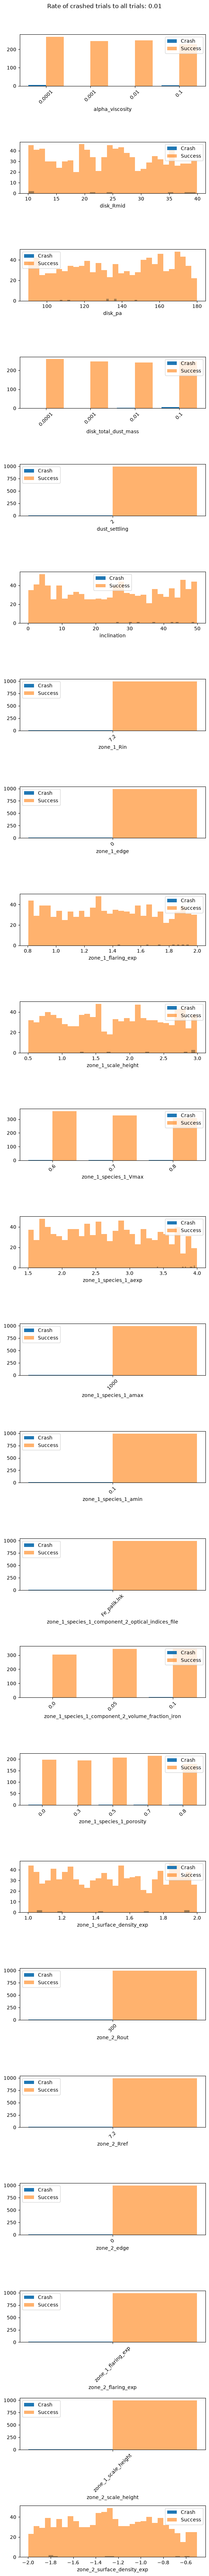

In [6]:

plot_crash_success_histograms(df, crashed_trials, successful_trials, param_cols, results_dir=results_dir, max_unique=20, nbins=30)

### Pairwise sanity checks (parameter vs cost)


[1.]
Processing budget: 1.0


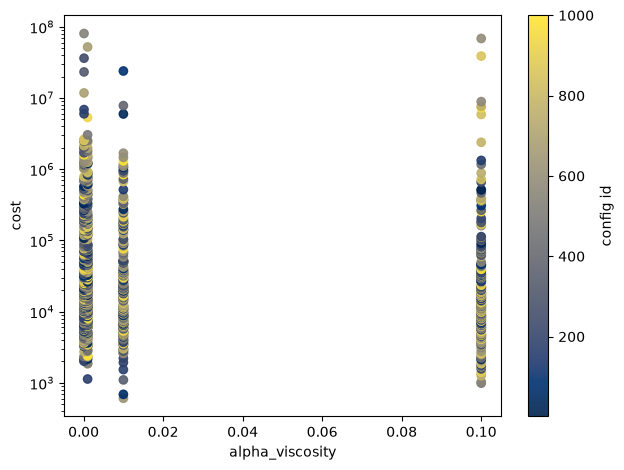

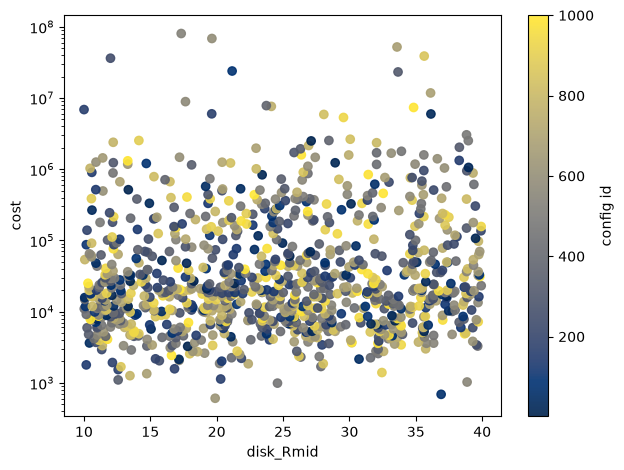

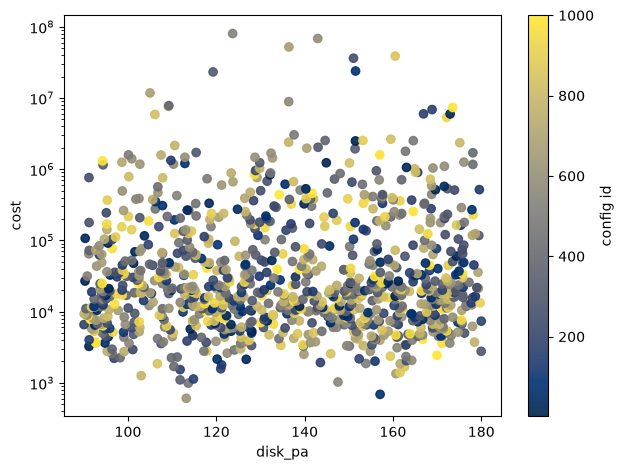

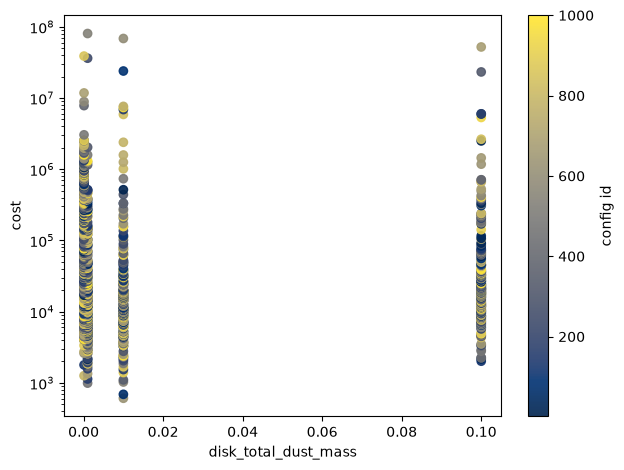

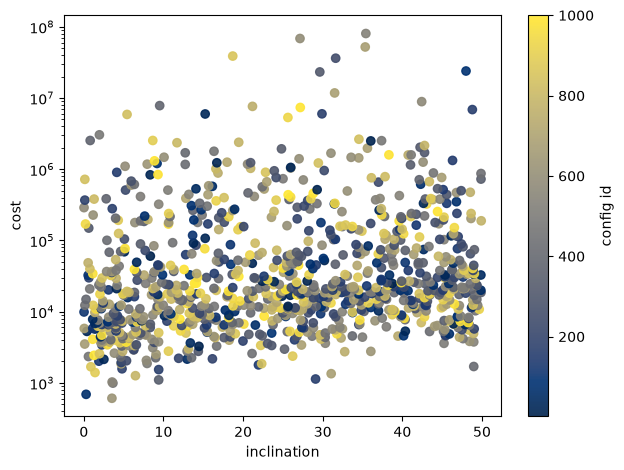

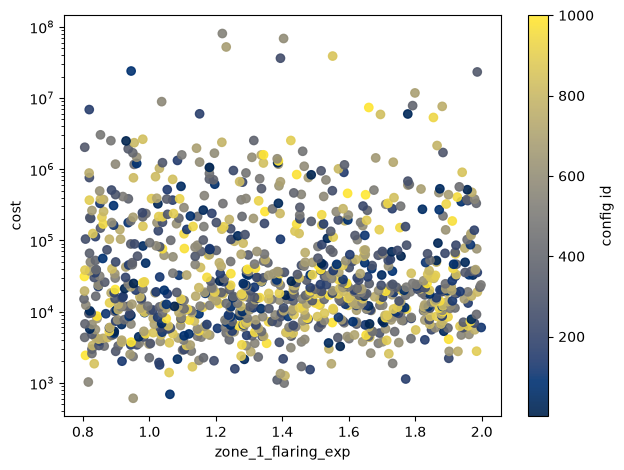

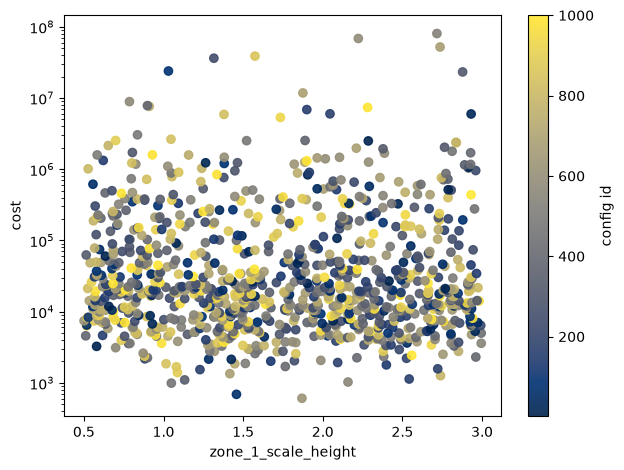

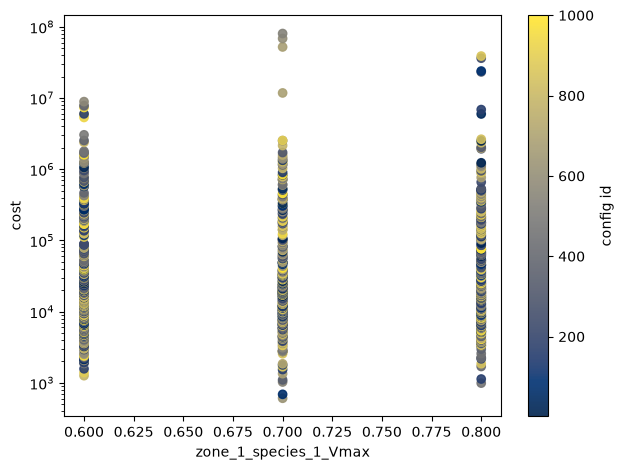

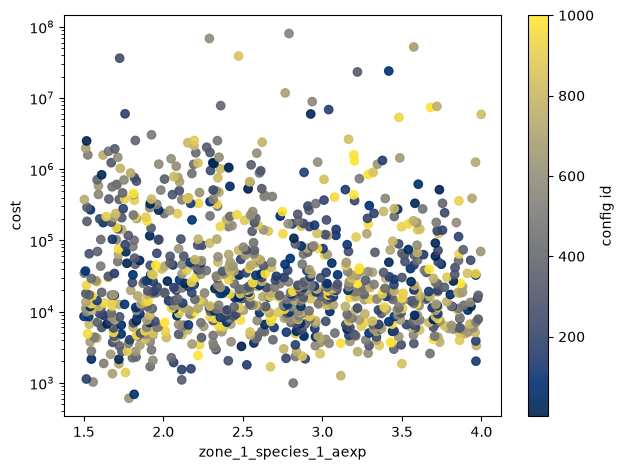

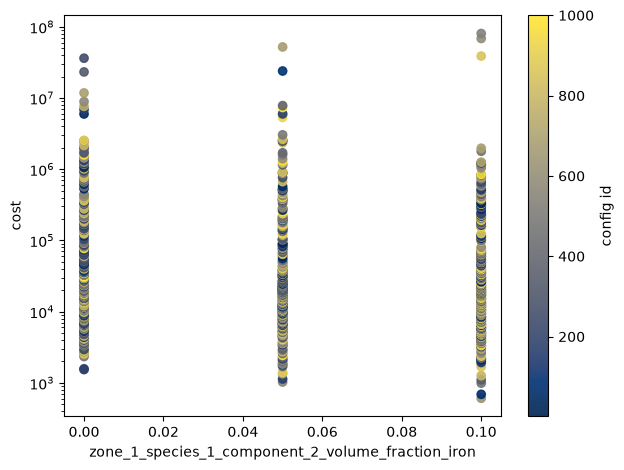

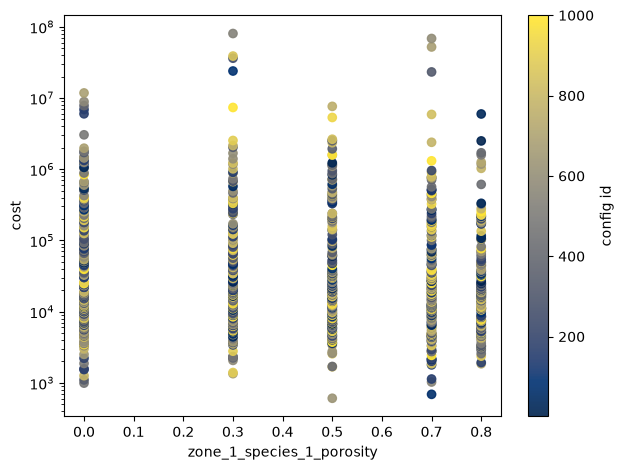

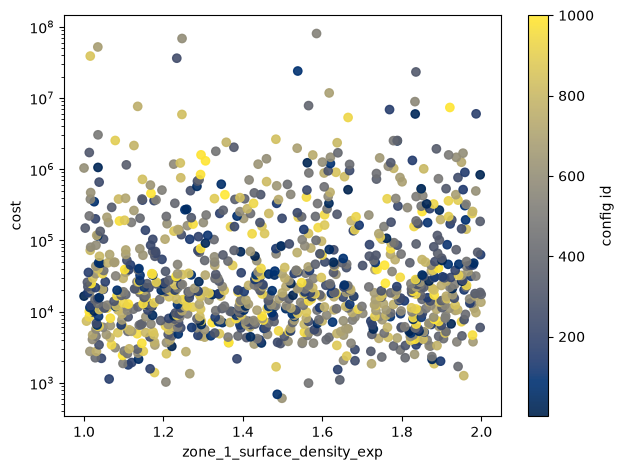

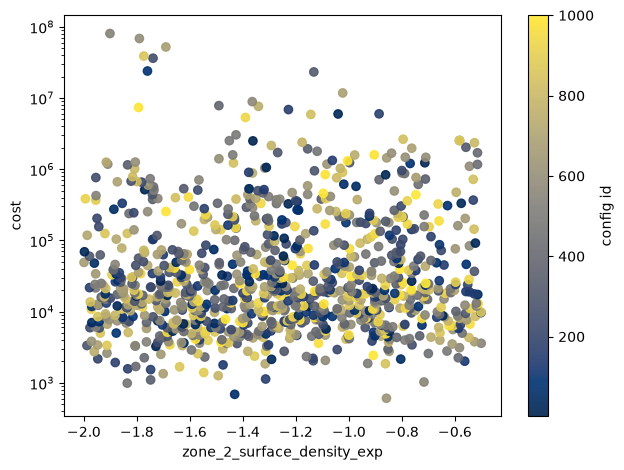

In [7]:
successful_trials=successful_trials[successful_trials['cost'] <1e8]

successful_trials_budget = successful_trials['budget'].unique()


print(successful_trials_budget)
for budget in successful_trials_budget:
    print(f"Processing budget: {budget}")
    successful_trials_budget_df = successful_trials[successful_trials['budget'] == budget]
    for p in param_cols:  # rename to your actual names
        if p in df.columns:
            if successful_trials_budget_df[p].unique().size > 1:
                plt.figure()
                sc=plt.scatter(successful_trials_budget_df[p], successful_trials_budget_df["cost"], c=successful_trials_budget_df["config_id"], cmap='cividis', alpha=0.9)
                plt.xlabel(p)
                plt.ylabel("cost")
                cbar = plt.colorbar(sc)
                cbar.set_label("config id")

                plt.yscale("log")  
                plt.tight_layout()
                plt.savefig(results_dir +f"scatter_{p}_budget_{budget}.png", dpi=150)
                plt.show()
                plt.close()


### Slice by budget (does the story change with fidelity?)

In [8]:
successful_trials.groupby("budget")["cost"].describe()#.to_csv(results_dir / "cost_by_budget.csv")


,count,mean,std,min,25%,50%,75%,max
budget,,,,,,,,
1.0,980.0,547107.882132,4.314688e+06,609.017644,8472.338336,19846.282382,80661.748748,8.042955e+07


### Parameter importance (fast, practical)

In [9]:
def binned_medians(successful_trials, param, bins=2):
    s = successful_trials[[param, "cost"]].dropna()
    s["bin"] = pd.qcut(s[param], q=bins, duplicates="drop")
    return s.groupby("bin", observed=True)["cost"].median().sort_values()

for p in ["zone_1_Rc", "zone_1_flaring_exp", "zone_1_dust_mass", "zone_1_species_1_porosity"]:
    if p in successful_trials.columns:
        bm = binned_medians(successful_trials[successful_trials["budget"] == successful_trials["budget"].max()], p)
        print(f"Binned medians for {p}:")
        print(bm)
        #bm.to_csv(results_dir / f"binned_median_{p}.csv")


Binned medians for zone_1_flaring_exp:
bin
(0.802, 1.388]    19234.789155
(1.388, 1.998]    19929.731898
Name: cost, dtype: float64
Binned medians for zone_1_species_1_porosity:
bin
(0.5, 0.8]       18039.384049
(-0.001, 0.5]    22067.201799
Name: cost, dtype: float64


### Clustering of “good” solutions (degeneracies)

In [10]:

percent_of_successful = len(successful_trials)*0.1

good = successful_trials[successful_trials["budget"] == successful_trials["budget"].max()].nsmallest(int(percent_of_successful), "cost")
good.describe()#.to_csv(results_dir / "good5_summary.csv")

,alpha_viscosity,disk_Rmid,disk_pa,disk_total_dust_mass,distance_pc,dust_settling,inclination,zone_1_Rin,zone_1_Rref,zone_1_edge,...,zone_1_surface_density_exp,zone_2_Rout,zone_2_Rref,zone_2_edge,zone_2_surface_density_exp,config_id,seed,budget,cost,time
count,98.000000,98.000000,98.000000,98.000000,98.0,98.0,98.000000,9.800000e+01,9.800000e+01,98.0,...,98.000000,98.0,9.800000e+01,98.0,98.000000,98.000000,98.0,98.0,98.000000,98.000000
mean,0.036467,23.225044,132.853579,0.014941,1220.0,2.0,14.036865,7.200000e+00,7.200000e+00,0.0,...,1.480735,300.0,7.200000e+00,0.0,-1.307093,513.571429,399247663.0,1.0,3040.808720,397.398639
std,0.045656,8.525212,25.687640,0.030691,0.0,0.0,12.999010,2.678235e-15,2.678235e-15,0.0,...,0.308357,0.0,2.678235e-15,0.0,0.425282,265.464697,0.0,0.0,1045.802049,197.409667
min,0.000100,10.175188,91.169078,0.000100,1220.0,2.0,0.112445,7.200000e+00,7.200000e+00,0.0,...,1.014970,300.0,7.200000e+00,0.0,-1.988131,2.000000,399247663.0,1.0,609.017644,152.582266
25%,0.001000,16.463810,111.301778,0.001000,1220.0,2.0,4.554502,7.200000e+00,7.200000e+00,0.0,...,1.169193,300.0,7.200000e+00,0.0,-1.665968,296.000000,399247663.0,1.0,2226.129269,259.492065
50%,0.010000,21.637029,127.703140,0.001000,1220.0,2.0,8.939584,7.200000e+00,7.200000e+00,0.0,...,1.490963,300.0,7.200000e+00,0.0,-1.379485,510.000000,399247663.0,1.0,3314.975414,326.682994
75%,0.100000,31.371407,156.068875,0.010000,1220.0,2.0,22.140463,7.200000e+00,7.200000e+00,0.0,...,1.786056,300.0,7.200000e+00,0.0,-0.907661,734.250000,399247663.0,1.0,3862.298690,475.362063
max,0.100000,39.661428,179.992511,0.100000,1220.0,2.0,48.966625,7.200000e+00,7.200000e+00,0.0,...,1.979002,300.0,7.200000e+00,0.0,-0.500527,996.000000,399247663.0,1.0,4533.979139,1052.739260


### Plot

In [11]:
curve = successful_trials.groupby(["config_id", "budget"])["cost"].min().reset_index()
curve#.to_csv(results_dir / "learning_curves.csv", index=False)


,config_id,budget,cost
0,1,1.0,1.187598e+04
1,2,1.0,3.261618e+03
2,3,1.0,6.027485e+04
3,4,1.0,2.694854e+04
4,5,1.0,2.497538e+06
...,...,...,...
975,996,1.0,3.740115e+03
976,997,1.0,2.047308e+04
977,998,1.0,4.382426e+05
978,999,1.0,2.506535e+04


## For the cornerplot


SMAC does not give a true posterior.
This corner plot represents a high-likelihood region sampled by Bayesian optimisation, not an MCMC posterior.
So... distribution of high-performing models:

In [12]:
# Restrict to highest fidelity
df_max = successful_trials[successful_trials["budget"] == successful_trials["budget"].max()].copy()

# Drop failed / NaN
df_max = df_max.dropna(subset=["cost"])

# Optional: keep only the best 30% of trials
q = 0.9
cost_cut = df_max["cost"].quantile(q)
df_sel = df_max[df_max["cost"] <= cost_cut]


In [13]:
exclude = {"config_id", "seed", "budget", "cost", "time", "status", 
           'distance_pc', "zone_1_Rref"}

param_cols = [c for c in df_sel.columns if c not in exclude]
param_cols


['alpha_viscosity',
 'disk_Rmid',
 'disk_pa',
 'disk_total_dust_mass',
 'dust_settling',
 'inclination',
 'zone_1_Rin',
 'zone_1_edge',
 'zone_1_flaring_exp',
 'zone_1_scale_height',
 'zone_1_species_1_Vmax',
 'zone_1_species_1_aexp',
 'zone_1_species_1_amax',
 'zone_1_species_1_amin',
 'zone_1_species_1_component_2_optical_indices_file',
 'zone_1_species_1_component_2_volume_fraction_iron',
 'zone_1_species_1_porosity',
 'zone_1_surface_density_exp',
 'zone_2_Rout',
 'zone_2_Rref',
 'zone_2_edge',
 'zone_2_flaring_exp',
 'zone_2_scale_height',
 'zone_2_surface_density_exp']

In [14]:
#just one function to do it
#WORKS

def make_corner_plot(
    df,
    params,
    *,
    budget=None,
    best_quantile=0.3,
    title=None,
    outfile="corner.png",
):

    d = df.copy()
    if budget is not None:
        d = d[d["budget"] == budget]

    d = d.dropna(subset=["cost"])
    cost_cut = d["cost"].quantile(best_quantile)
    d = d[d["cost"] <= cost_cut]
    if len(d) == 0:
        print("No data to plot after filtering by budget and cost quantile.")
        return
    params_corner = []
    for p in params:
        if p not in d.columns:
            raise ValueError(f"Parameter '{p}' not found in DataFrame columns.")
        if d[p].unique().size >= 2:
            params_corner.append(p)
        else:
            print(f"Parameter '{p}' has less than 2 unique values in the filtered DataFrame.")


    if len(params_corner) == 0:
        print("No valid parameters to plot after filtering.")
        return
    data = d[params_corner].values

    fig = corner.corner(
        data,
        labels=params_corner,
        quantiles=[0.16, 0.5, 0.84],
        weights=1.0 / d["cost"].values,
        show_titles=True,
        wrap_title_quantiles=True,
        title_fmt=".3g"  
    )
    plt.suptitle(title, fontsize=14, y=1.01)
    fig.savefig(outfile, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)




       zone_1_flaring_exp  zone_1_species_1_porosity
count          882.000000                 882.000000
mean             1.392218                   0.468254
std              0.344689                   0.283426
min              0.803220                   0.000000
25%              1.095318                   0.300000
50%              1.394144                   0.500000
75%              1.668528                   0.700000
max              1.998443                   0.800000


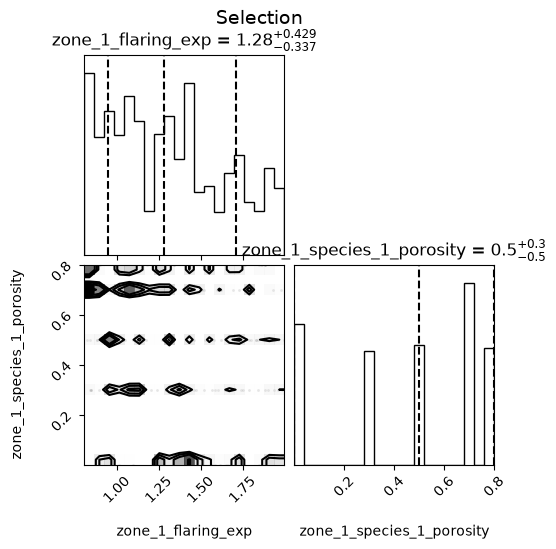

In [15]:
param_cols=[ "zone_1_flaring_exp", "zone_1_species_1_porosity"]
print(df_sel[param_cols].describe())

make_corner_plot(
    df_sel,
    params=param_cols,
    budget=df_sel["budget"].max(),
    outfile=results_dir+ "corner_best.png",
    title="Selection"
)


## setting up subgroups of parameters for corner plots

Parameters for 'Grid setup parameters': []
[]
Parameters for 'Disk orientation parameters': ['disk_pa', 'distance_pc']
Parameter 'distance_pc' has less than 2 unique values in the filtered DataFrame.
['disk_pa']
Parameters for 'Disk geometry parameters': ['disk_Rmid', 'zone_1_Rin', 'zone_1_Rref', 'zone_1_edge', 'zone_1_flaring_exp', 'zone_1_scale_height', 'zone_1_surface_density_exp', 'zone_2_Rout', 'zone_2_Rref', 'zone_2_edge', 'zone_2_flaring_exp', 'zone_2_scale_height', 'zone_2_surface_density_exp']
Parameter 'zone_1_Rin' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_1_Rref' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_1_edge' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_2_Rout' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_2_Rref' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_2_edge' has less than 2 unique values in the filtered DataFrame.
Paramet

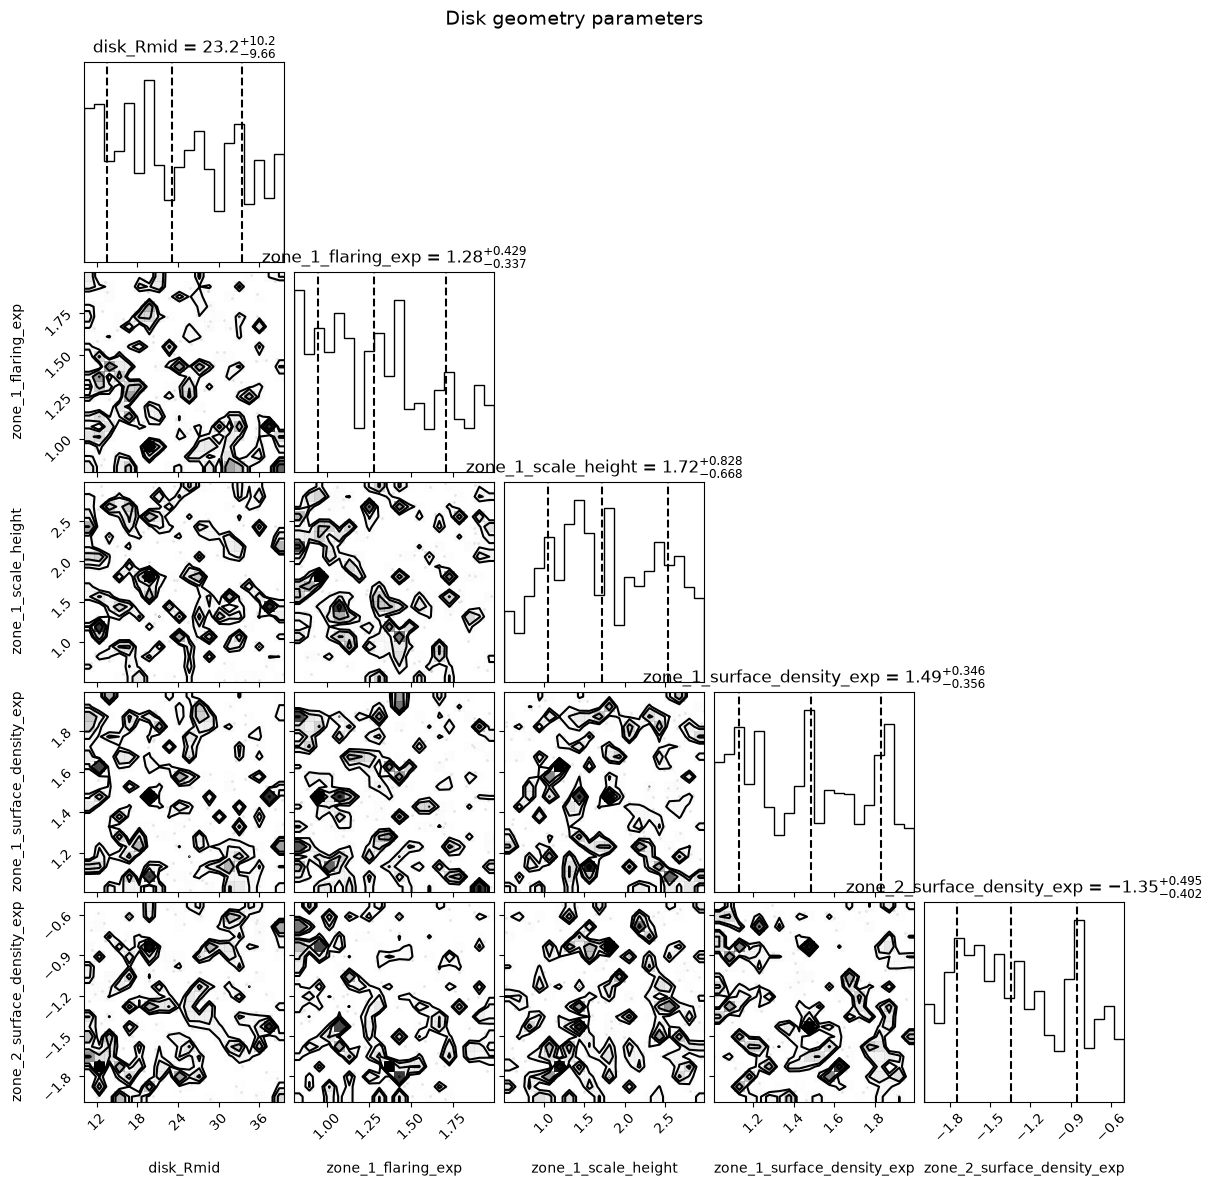

Parameters for 'Dust distribution parameters': ['alpha_viscosity', 'disk_Rmid', 'dust_settling']
Parameter 'dust_settling' has less than 2 unique values in the filtered DataFrame.
['alpha_viscosity', 'disk_Rmid']
Corner plot for Dust distribution parameters:


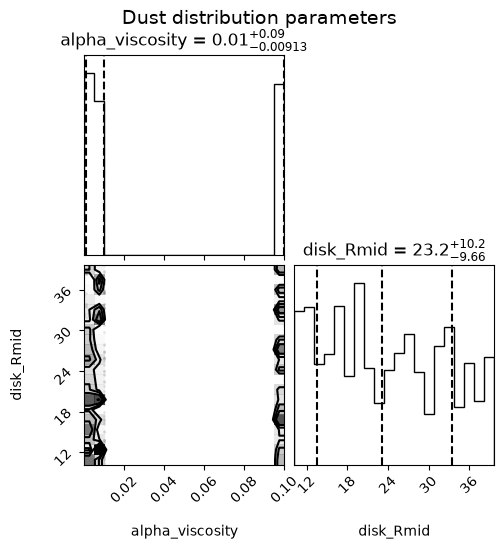

Parameters for 'Dust grain parameters': ['zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_amax', 'zone_1_species_1_amin', 'zone_1_species_1_porosity']
Parameter 'zone_1_species_1_amax' has less than 2 unique values in the filtered DataFrame.
Parameter 'zone_1_species_1_amin' has less than 2 unique values in the filtered DataFrame.
['zone_1_species_1_Vmax', 'zone_1_species_1_aexp', 'zone_1_species_1_porosity']
Corner plot for Dust grain parameters:


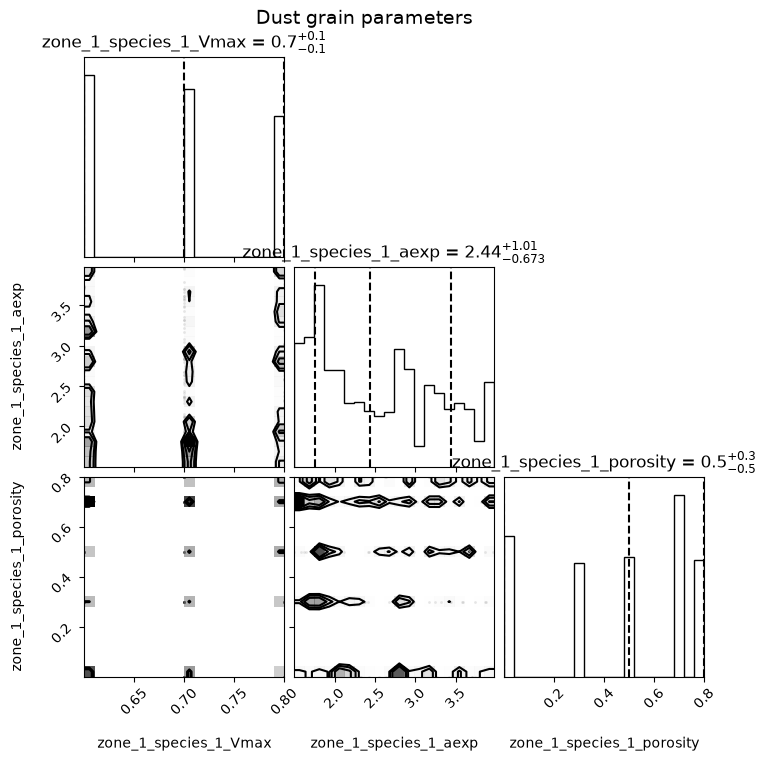

Parameters for 'Star parameters': []
[]


In [16]:
#all parameters

grid_setup_parameters=["grid_geometry", "n_rad", "nz", "n_az", "n_rad_in", "grid_nx", "grid_ny", "grid_size"]
disk_orientation_parameters=["imin", "imax", "n_incl", "centered", "az_min", "az_max", "distance_pc", "disk_pa"]
disk_geometry_parameters=["disk_Rmid","zone_1_scale_height", "zone_1_Rref", "zone_1_vertical_profile_exponent", "zone_1_Rin", "zone_1_edge", "zone_1_Rout", "zone_1_Rc", "zone_1_flaring_exp", "zone_1_surface_density_exp", "zone_1_-gamma_exp", 
                        "zone_2_scale_height", "zone_2_Rref", "zone_2_vertical_profile_exponent", "zone_2_Rin", "zone_2_edge", "zone_2_Rout", "zone_2_Rc", "zone_2_flaring_exp", "zone_2_surface_density_exp", "zone_2_-gamma_exp"]

dust_distribution_parameters=["dust_settling", "exp_strat", "a_strat", "dust_radial_migration", "sublimate_dust", "hydrostatic_equilibrium", "viscous_heating", "alpha_viscosity",
                          "zone_1_dust_mass","zone_2_dust_mass", "disk_Rmid", "zone_1_gas_to_dust"]
dust_grain_parameters=["zone_1_species_1_grain_type", "zone_1_species_1_N_components", "zone_1_species_1_mixing_rule", "zone_1_species_1_porosity", "zone_1_species_1_mass_fraction", "zone_1_species_1_Vmax", "zone_1_species_1_optical_indices_file", "zone_1_species_1_volume_fraction", "zone_1_species_1_heating_method",
                       "zone_1_species_1_amin", "zone_1_species_1_amax", "zone_1_species_1_aexp", "zone_1_species_1_n_grains"]
star_parameters=["star_1_Temp", "star_1_R", "star_1_M", "star_1_x", "star_1_y", "star_1_z", "star_1_autometic_spectrum", "star_1_spectrum_file", "star_1_fUV", "star_1_slope_fUV"]  


titles={"Grid setup parameters": grid_setup_parameters,
        "Disk orientation parameters": disk_orientation_parameters,
        "Disk geometry parameters": disk_geometry_parameters,
        "Dust distribution parameters": dust_distribution_parameters,
        "Dust grain parameters": dust_grain_parameters,
        "Star parameters": star_parameters}

for title in titles.keys():
    param_subset = titles[title]
    param_cols_set = [c for c in df_sel.columns if c in param_subset]
    param_cols_corner = []  # Initialize a list to keep track of parameters with less than 2 unique values
    print(f"Parameters for '{title}': {param_cols_set}")
    for p in param_cols_set:
        if df_sel[p].unique().size >= 2:
            param_cols_corner.append(p) 
        else:
            print(f"Parameter '{p}' has less than 2 unique values in the filtered DataFrame.")

    print(param_cols_corner)

    if len(param_cols_corner)>1:
        print(f"Corner plot for {title}:")
        
        #print(df_sel[param_cols_set].describe())

        make_corner_plot(
            df_sel,
            params=param_cols_corner,
            budget=df_sel["budget"].max(),
            title=title,
            outfile=results_dir+ f"corner_{title}_best.png"
        )

